# Experiment: Linear Regression and Evaluation Metrics
Predicting exam marks from study hours: MAE, MSE, RMSE and R² Score.

**Part A:** Numerical problem (8 students)  
**Part B:** Real dataset (scikit-learn Diabetes dataset)

## Part A: Numerical Solution

In [2]:
%pip install numpy pandas matplotlib seaborn scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

x = np.array([1, 2, 3, 4, 5, 6, 7, 8], dtype=float)
y = np.array([38, 45, 50, 58, 62, 71, 74, 83], dtype=float)

b1 = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean())**2)
b0 = y.mean() - b1 * x.mean()
y_hat = b0 + b1 * x
err = y - y_hat

mae  = np.mean(np.abs(err))
mse  = np.mean(err**2)
rmse = np.sqrt(mse)
r2   = 1 - np.sum(err**2) / np.sum((y - y.mean())**2)

print(f"Slope b1 = {b1:.4f}   Intercept b0 = {b0:.4f}")
print(f"MAE  = {mae:.4f}")
print(f"MSE  = {mse:.4f}")
print(f"RMSE = {rmse:.4f}")
print(f"R2   = {r2:.4f}  ({r2*100:.2f}%)")


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Slope b1 = 6.2738   Intercept b0 = 31.8929
MAE  = 0.9881
MSE  = 1.2158
RMSE = 1.1026
R2   = 0.9942  (99.42%)


### Part A: Visualizations

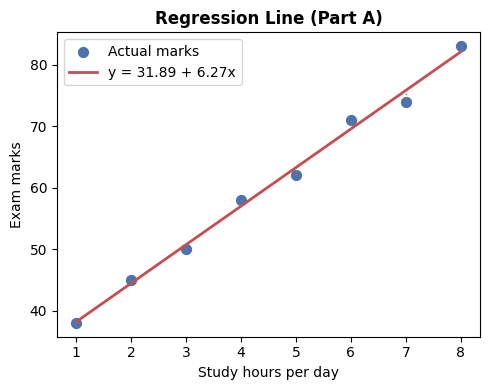

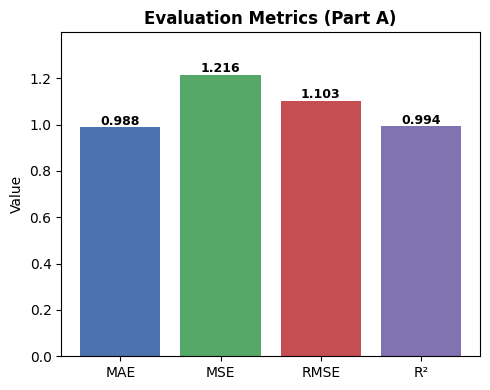

In [3]:
# Fig. 1: Regression line with errors
plt.figure(figsize=(5, 4))
plt.scatter(x, y, color="#4C72B0", s=50, label="Actual marks")
plt.plot(x, y_hat, color="#C44E52", lw=2, label=f"y = {b0:.2f} + {b1:.2f}x")
for xi, yi, yhi in zip(x, y, y_hat):
    plt.plot([xi, xi], [yi, yhi], color="gray", lw=1, ls=":")
plt.xlabel("Study hours per day"); plt.ylabel("Exam marks")
plt.title("Regression Line (Part A)", fontweight="bold"); plt.legend()
plt.tight_layout(); plt.savefig("fig1.png", dpi=150); plt.show()

def bar_chart(names, vals, title, fname):
    plt.figure(figsize=(5, 4))
    bars = plt.bar(names, vals, color=["#4C72B0", "#55A868", "#C44E52", "#8172B2"])
    for b, v in zip(bars, vals):
        plt.text(b.get_x() + b.get_width()/2, v*1.01, f"{v:.3f}", ha="center", fontweight="bold", fontsize=9)
    plt.ylim(0, max(vals)*1.15); plt.ylabel("Value"); plt.title(title, fontweight="bold")
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

# Fig. 2: Metrics
bar_chart(["MAE", "MSE", "RMSE", "R²"], [mae, mse, rmse, r2], "Evaluation Metrics (Part A)", "fig2.png")

## Part B: Real Dataset Workflow

In [4]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = load_diabetes(as_frame=True).frame
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum(), "| Duplicate rows:", df.duplicated().sum())
df.head()

Shape: (442, 11)
Missing values: 0 | Duplicate rows: 0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [5]:
X = df.drop(columns=["target"]); y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", len(X_train), " Test:", len(X_test))

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

model = LinearRegression().fit(X_train_s, y_train)
y_pred = model.predict(X_test_s)

MAE  = mean_absolute_error(y_test, y_pred)
MSE  = mean_squared_error(y_test, y_pred)
RMSE = np.sqrt(MSE)
R2   = r2_score(y_test, y_pred)
print(f"MAE={MAE:.4f}  MSE={MSE:.4f}  RMSE={RMSE:.4f}  R2={R2:.4f}")

Train: 353  Test: 89
MAE=42.7941  MSE=2900.1936  RMSE=53.8534  R2=0.4526


### Part B: Visualizations

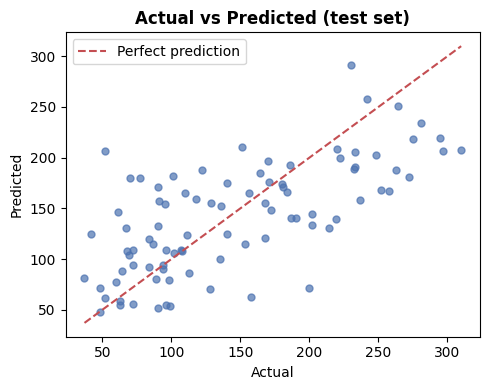

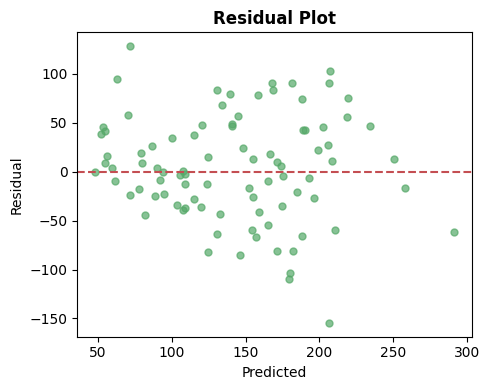

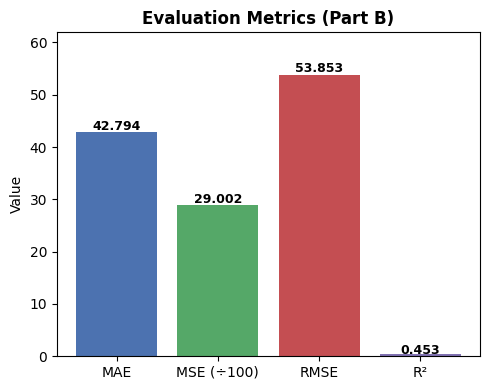

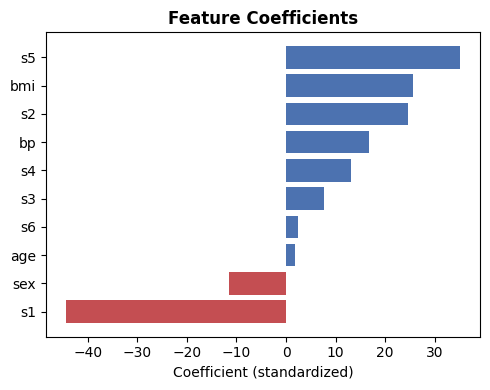

In [6]:
# Fig. 4: Actual vs predicted
plt.figure(figsize=(5, 4))
plt.scatter(y_test, y_pred, color="#4C72B0", alpha=0.7, s=25)
lo, hi = min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())
plt.plot([lo, hi], [lo, hi], "--", color="#C44E52", label="Perfect prediction")
plt.xlabel("Actual"); plt.ylabel("Predicted"); plt.title("Actual vs Predicted (test set)", fontweight="bold"); plt.legend()
plt.tight_layout(); plt.savefig("fig4.png", dpi=150); plt.show()

# Fig. 5: Residual plot
residuals = y_test - y_pred
plt.figure(figsize=(5, 4))
plt.scatter(y_pred, residuals, color="#55A868", alpha=0.7, s=25)
plt.axhline(0, color="#C44E52", ls="--")
plt.xlabel("Predicted"); plt.ylabel("Residual"); plt.title("Residual Plot", fontweight="bold")
plt.tight_layout(); plt.savefig("fig5.png", dpi=150); plt.show()

# Fig. 6: Metrics
bar_chart(["MAE", "MSE (÷100)", "RMSE", "R²"], [MAE, MSE/100, RMSE, R2], "Evaluation Metrics (Part B)", "fig6.png")

# Fig. 7: Feature coefficients
coef = pd.Series(model.coef_, index=X.columns).sort_values()
plt.figure(figsize=(5, 4))
plt.barh(coef.index, coef.values, color=["#C44E52" if v < 0 else "#4C72B0" for v in coef.values])
plt.xlabel("Coefficient (standardized)"); plt.title("Feature Coefficients", fontweight="bold")
plt.tight_layout(); plt.savefig("fig7.png", dpi=150); plt.show()

## Conclusion
The regression line for Part A explains about 99.4% of the variation in marks. On the real Diabetes dataset, the linear model explains about 45% of the variation, showing that real data is noisier than a small textbook example.